In [ ]:
from google.colab import drive
import os, subprocess

drive.mount("/content/drive")

work = "/content/drive/MyDrive/computer_vision"
os.chdir(work)

data_dir = "/root/crack-detect/data"
if not os.path.exists(data_dir + "/Bridge_Crack_Image"):
    os.makedirs(data_dir, exist_ok=True)
    subprocess.run(["unzip", "-q", work + "/archive.zip", "Bridge_Crack_Image/*", "-d", data_dir], check=True)

print(os.getcwd(), os.listdir(data_dir))

Mounted at /content/drive
/content/drive/MyDrive/computer_vision ['Bridge_Crack_Image']


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("manifest.csv")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
torch.manual_seed(42)
np.random.seed(42)

cuda


In [ ]:
SIZE = 224
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class CrackDS(Dataset):
    def __init__(self, d, tf):
        self.p = d.path.tolist()
        self.y = d.label.tolist()
        self.tf = tf
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

TRAIN_SUBSET = None
VAL_SUBSET = None
EPOCHS = 6

def take(d, n):
    if n is None or n >= len(d):
        return d
    return train_test_split(d, train_size=n, stratify=d.label, random_state=42)[0]

train_df = take(df[df.split == "train"], TRAIN_SUBSET)
val_df = take(df[df.split == "val"], VAL_SUBSET)
print(len(train_df), len(val_df))

train_dl = DataLoader(CrackDS(train_df, train_tf), batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(CrackDS(val_df, eval_tf), batch_size=64, shuffle=False, num_workers=2)

counts = train_df.label.value_counts().sort_index().values
weights = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32).to(device)
crit = nn.CrossEntropyLoss(weight=weights)
print(counts, weights)

45000 5000
[39600  5400] tensor([0.5682, 4.1667], device='cuda:0')


In [ ]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train)
    total, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(train):
            out = model(x)
            loss = crit(out, y)
        if train:
            opt.zero_grad()
            loss.backward()
            opt.step()
        total += loss.item() * len(y)
        ys += y.tolist()
        ps += out.argmax(1).tolist()
    return total / len(ys), accuracy_score(ys, ps), f1_score(ys, ps)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s]


In [ ]:
history = []

for p in model.parameters():
    p.requires_grad = False
for p in model.fc.parameters():
    p.requires_grad = True

opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
for ep in range(2):
    tr = run_epoch(train_dl, opt)
    va = run_epoch(val_dl)
    history.append((*tr, *va))
    print(f"head epoch {ep+1} | train loss {tr[0]:.4f} f1 {tr[2]:.4f} | val loss {va[0]:.4f} f1 {va[2]:.4f}")

head epoch 1 | train loss 0.2423 f1 0.7447 | val loss 0.2513 f1 0.6403
head epoch 2 | train loss 0.1685 f1 0.8126 | val loss 0.1801 f1 0.7467


In [ ]:
for p in model.parameters():
    p.requires_grad = True

opt = torch.optim.Adam(model.parameters(), lr=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=1)
best_f1, patience, bad = 0.0, 3, 0

for ep in range(EPOCHS):
    tr = run_epoch(train_dl, opt)
    va = run_epoch(val_dl)
    history.append((*tr, *va))
    sched.step(va[2])
    print(f"epoch {ep+1} | train loss {tr[0]:.4f} f1 {tr[2]:.4f} | val loss {va[0]:.4f} f1 {va[2]:.4f}")
    if va[2] > best_f1:
        best_f1, bad = va[2], 0
        torch.save(model.state_dict(), "crack_resnet18.pt")
    else:
        bad += 1
        if bad >= patience:
            print("early stop")
            break

print("best val f1:", best_f1)

epoch 1 | train loss 0.0543 f1 0.9445 | val loss 0.0360 f1 0.9747
epoch 2 | train loss 0.0440 f1 0.9518 | val loss 0.0347 f1 0.9631
epoch 3 | train loss 0.0367 f1 0.9524 | val loss 0.0236 f1 0.9831
epoch 4 | train loss 0.0356 f1 0.9546 | val loss 0.0232 f1 0.9736
epoch 5 | train loss 0.0342 f1 0.9567 | val loss 0.0241 f1 0.9787
epoch 6 | train loss 0.0267 f1 0.9632 | val loss 0.0151 f1 0.9761
early stop
best val f1: 0.9831013916500994


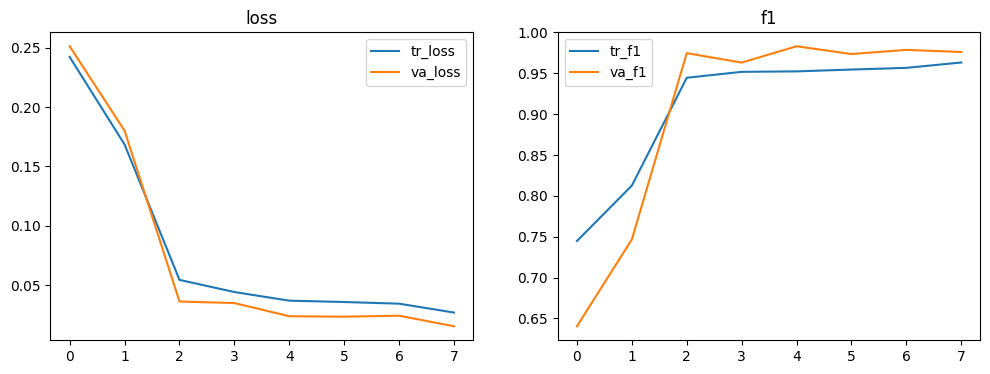

In [ ]:
h = pd.DataFrame(history, columns=["tr_loss", "tr_acc", "tr_f1", "va_loss", "va_acc", "va_f1"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h[["tr_loss", "va_loss"]].plot(ax=ax[0], title="loss")
h[["tr_f1", "va_f1"]].plot(ax=ax[1], title="f1")
plt.show()